# PhishingDetectorAI — Entrenamiento y evaluación
**Objetivo:** entrenar un clasificador supervisado que estime si una URL es phishing o legítima usando exclusivamente el texto de la URL.

**Dataset:** PhiUSIIL Phishing URL (Website), UCI Machine Learning Repository, ID 967. El conjunto contiene 235.795 registros: 134.850 legítimos y 100.945 phishing. En la fuente original `Label=1` significa legítima y `Label=0` significa phishing. En este notebook invertimos esa codificación para usar `1=phishing` y `0=legítima`.

**Decisión metodológica:** aunque el dataset incluye variables derivadas de la página web, este proyecto utiliza únicamente la columna `URL`. Así la aplicación puede analizar una URL nueva sin visitar la página ni necesitar HTML.

> Advertencia: una predicción no garantiza que una URL sea segura. El sistema es una herramienta de apoyo y no debe abrir ni visitar los enlaces analizados.

## 1. Instalación e importación

In [1]:
!pip -q install ucimlrepo joblib scikit-learn pandas numpy matplotlib seaborn

In [2]:
import os, re, json, warnings
from urllib.parse import urlsplit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.base import clone

RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)
warnings.filterwarnings("ignore")

## 2. Descarga del dataset desde UCI

In [3]:
# Dataset oficial UCI: PhiUSIIL Phishing URL (Website), ID 967
dataset = fetch_ucirepo(id=967)

X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

print("Dimensiones de características:", X_raw.shape)
print("Columnas de características:", list(X_raw.columns))
print("Columnas objetivo:", list(y_raw.columns))
display(X_raw.head())
display(y_raw.head())

Dimensiones de características: (235795, 54)
Columnas de características: ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']
Columnas objetivo: ['label']

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,1,0,0,1,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,0,1,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,0,1,10,2,7,42,2,5
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,0,1,1,1,3,27,15,22,1,31
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,1,0,1,244,15,34,72,1,85


,label
0,1
1,1
2,1
3,1
4,1


## 3. Preparación: conservar únicamente URL y etiqueta

In [4]:
if "URL" not in X_raw.columns:
    raise ValueError("No se encontró la columna URL en el dataset UCI.")

url_col = X_raw["URL"].astype("string")
target_col = y_raw.iloc[:, 0]

df = pd.DataFrame({
    "url": url_col,
    "original_label": pd.to_numeric(target_col, errors="coerce")
})

df = df.dropna(subset=["url", "original_label"])
df["url"] = df["url"].str.strip()
df = df[df["url"].str.len() > 0]
df = df[df["original_label"].isin([0, 1])]
df = df.drop_duplicates(subset=["url"]).reset_index(drop=True)

# En PhiUSIIL: Label 0 = phishing, Label 1 = legítima.
# Para este proyecto: 1 = phishing, 0 = legítima.
df["phishing"] = (df["original_label"] == 0).astype(int)
df = df[["url", "phishing"]]

print("Registros después de limpieza:", len(df))
print(df["phishing"].value_counts().rename(index={0:"Legítima", 1:"Phishing"}))
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))

Registros después de limpieza: 235370
phishing
Legítima    134850
Phishing    100520
Name: count, dtype: int64


,url,phishing
142503,http://www.s107008.hostde20.fornex.host,1
175071,https://www.espresso4you.nl,0
33614,https://www.mazzios.com,0
68528,http://www.digitalkhulna.com,1
121610,http://www.pathregretforce.com,1


## 4. Exploración de datos

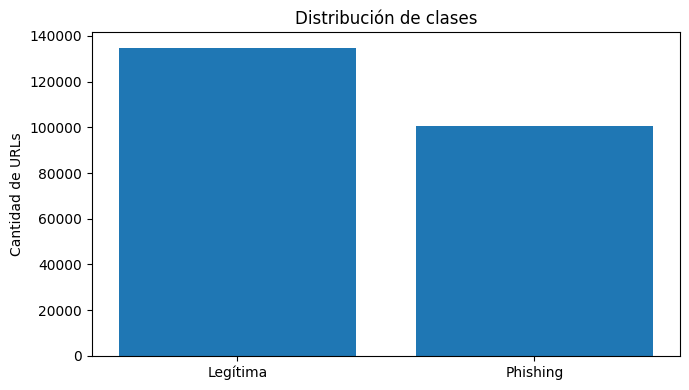

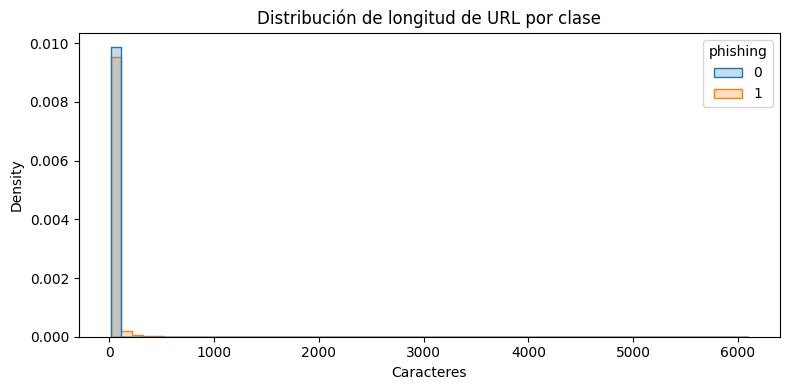

URLs duplicadas: 0
Valores nulos: {'url': 0, 'phishing': 0, 'longitud_url': 0}


In [5]:
class_counts = df["phishing"].value_counts().sort_index()
class_names = ["Legítima", "Phishing"]

plt.figure(figsize=(7,4))
plt.bar(class_names, [class_counts.get(0,0), class_counts.get(1,0)])
plt.title("Distribución de clases")
plt.ylabel("Cantidad de URLs")
plt.tight_layout()
plt.savefig("reports/distribucion_clases.png", dpi=150)
plt.show()

df["longitud_url"] = df["url"].str.len()
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="longitud_url", hue="phishing", bins=60, element="step", stat="density", common_norm=False)
plt.title("Distribución de longitud de URL por clase")
plt.xlabel("Caracteres")
plt.tight_layout()
plt.savefig("reports/longitud_urls.png", dpi=150)
plt.show()

print("URLs duplicadas:", df["url"].duplicated().sum())
print("Valores nulos:", df.isna().sum().to_dict())

## 5. División de entrenamiento, validación y prueba

Se realiza una división estratificada para conservar aproximadamente la proporción de clases. Se elimina primero cualquier URL duplicada exacta. La prueba queda separada y no se utiliza para elegir hiperparámetros.

**Limitación metodológica:** URLs de un mismo dominio pueden aparecer en particiones distintas. Por eso los resultados representan el rendimiento sobre URLs no vistas, pero no garantizan generalización a dominios completamente nuevos.

In [6]:
X = df["url"].astype(str)
y = df["phishing"].astype(int)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train_val
)

print("Entrenamiento:", len(X_train))
print("Validación:", len(X_val))
print("Prueba:", len(X_test))
print("\nProporciones de phishing:")
print("Train:", round(y_train.mean(), 4), "Validation:", round(y_val.mean(), 4), "Test:", round(y_test.mean(), 4))

Entrenamiento: 150636
Validación: 37660
Prueba: 47074

Proporciones de phishing:
Train: 0.4271 Validation: 0.4271 Test: 0.4271


## 6. Vectorización y entrenamiento de modelos

TF-IDF a nivel de caracteres representa fragmentos de 3 a 5 caracteres. Es apropiado para URLs porque puede aprender patrones de texto sin depender de un vocabulario de palabras tradicional. Se comparan Naive Bayes y Regresión Logística usando exactamente la misma representación.

In [7]:
def build_pipeline(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            max_features=250000,
            sublinear_tf=True,
            lowercase=True,
            dtype=np.float32
        )),
        ("classifier", classifier)
    ])

candidates = {
    "MultinomialNB": build_pipeline(MultinomialNB(alpha=0.5)),
    "LogisticRegression": build_pipeline(
        LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            solver="liblinear",
            random_state=RANDOM_STATE
        )
    )
}

validation_results = []
trained_candidates = {}

for name, pipeline in candidates.items():
    print("Entrenando:", name)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_val)
    if hasattr(pipeline, "predict_proba"):
        score = pipeline.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, score)
    else:
        auc = np.nan
    row = {
        "modelo": name,
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "roc_auc": auc
    }
    validation_results.append(row)
    trained_candidates[name] = pipeline

validation_df = pd.DataFrame(validation_results).sort_values("f1", ascending=False)
display(validation_df)
best_name = validation_df.iloc[0]["modelo"]
best_model = trained_candidates[best_name]
print("Modelo seleccionado según F1 de validación:", best_name)

Entrenando: MultinomialNB
Entrenando: LogisticRegression


,modelo,accuracy,precision,recall,f1,roc_auc
1,LogisticRegression,0.995937,1.000000,0.990487,0.995221,0.998585
0,MultinomialNB,0.953903,0.993533,0.897911,0.943305,0.994385


Modelo seleccionado según F1 de validación: LogisticRegression


## 7. Evaluación final con el conjunto de prueba

In [8]:
test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)[:, 1]

metrics = {
    "modelo": best_name,
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1": float(f1_score(y_test, test_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, test_prob))
}
print(json.dumps(metrics, indent=2, ensure_ascii=False))
print("\nReporte de clasificación:")
print(classification_report(y_test, test_pred, target_names=["Legítima", "Phishing"], zero_division=0))

{
  "modelo": "LogisticRegression",
  "accuracy": 0.9961762331648043,
  "precision": 1.0,
  "recall": 0.9910465578989256,
  "f1": 0.9955031477965425,
  "roc_auc": 0.9989356809182537
}

Reporte de clasificación:
              precision    recall  f1-score   support

    Legítima       0.99      1.00      1.00     26970
    Phishing       1.00      0.99      1.00     20104

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



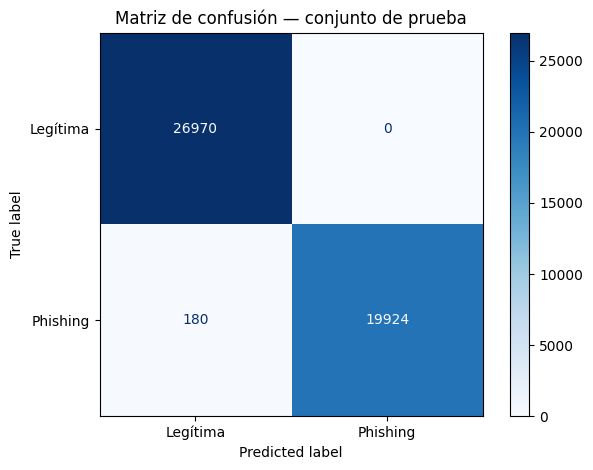

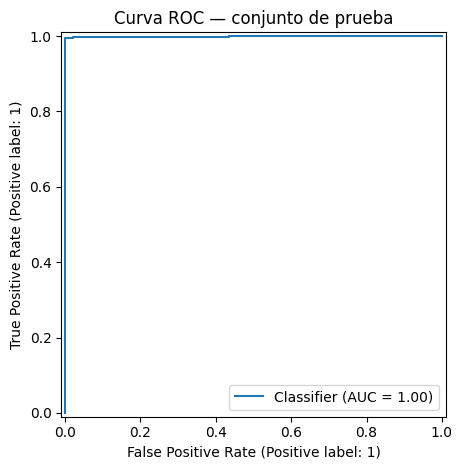

In [9]:
cm = confusion_matrix(y_test, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Legítima", "Phishing"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión — conjunto de prueba")
plt.tight_layout()
plt.savefig("reports/matriz_confusion.png", dpi=160)
plt.show()

RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("Curva ROC — conjunto de prueba")
plt.tight_layout()
plt.savefig("reports/curva_roc.png", dpi=160)
plt.show()

## 8. Análisis de errores

In [10]:
errors = pd.DataFrame({
    "url": X_test.reset_index(drop=True),
    "real": y_test.reset_index(drop=True),
    "prediccion": pd.Series(test_pred)
})
errors = errors[errors["real"] != errors["prediccion"]]
errors["real"] = errors["real"].map({0:"Legítima", 1:"Phishing"})
errors["prediccion"] = errors["prediccion"].map({0:"Legítima", 1:"Phishing"})
print("Cantidad de errores:", len(errors))
display(errors.head(20))

Cantidad de errores: 180


,url,real,prediccion
598,https://www.geniusinu.net/#,Phishing,Legítima
748,https://www.cfg.me,Phishing,Legítima
1037,https://www.michelonturismo.com.br,Phishing,Legítima
1669,https://www.tostudydrycleaning.ru,Phishing,Legítima
1772,https://www.tracker.dhsgovn.com/,Phishing,Legítima
2151,https://www.sfr-paiement-abonnement.fr/,Phishing,Legítima
2199,https://www.remzicakar.com.tr/blue/,Phishing,Legítima
2579,https://www.netflix-vn.com,Phishing,Legítima
2915,https://www.hash-flow.cf/,Phishing,Legítima
3516,https://www.instagram-apple.com,Phishing,Legítima


## 9. Guardar el modelo serializado y resultados

In [11]:
artifact = {
    "pipeline": best_model,
    "model_name": best_name,
    "positive_class": "phishing",
    "label_mapping": {"0": "legítima", "1": "phishing"},
    "dataset": "UCI PhiUSIIL Phishing URL (Website), ID 967",
    "random_state": RANDOM_STATE
}
joblib.dump(artifact, "models/phishing_detector.joblib", compress=3)

with open("reports/metricas_prueba.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

validation_df.to_csv("reports/comparacion_validacion.csv", index=False)
print("Modelo guardado en models/phishing_detector.joblib")
print("Métricas guardadas en reports/metricas_prueba.json")

Modelo guardado en models/phishing_detector.joblib
Métricas guardadas en reports/metricas_prueba.json


## 10. Prueba de inferencia con URLs nuevas

In [12]:
def predict_url(url, model_artifact):
    if not isinstance(url, str) or not url.strip():
        raise ValueError("La URL no puede estar vacía.")
    clean_url = url.strip()
    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", clean_url):
        clean_url = "https://" + clean_url
    parsed = urlsplit(clean_url)
    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("Ingresa una URL válida con dominio.")
    pipeline = model_artifact["pipeline"]
    prediction = int(pipeline.predict([clean_url])[0])
    probability = float(pipeline.predict_proba([clean_url])[0][1])
    return {
        "url": clean_url,
        "prediction": "Phishing" if prediction == 1 else "Legítima",
        "phishing_probability": probability
    }

loaded_artifact = joblib.load("models/phishing_detector.joblib")
examples = [
    "https://www.wikipedia.org/",
    "https://www.google.com/",
    "http://secure-account-verification.example-login.test/confirm"
]
for item in examples:
    try:
        print(predict_url(item, loaded_artifact))
    except ValueError as error:
        print("Entrada inválida:", error)

{'url': 'https://www.wikipedia.org/', 'prediction': 'Legítima', 'phishing_probability': 0.012226847497049711}
{'url': 'https://www.google.com/', 'prediction': 'Legítima', 'phishing_probability': 0.03997239201288077}
{'url': 'http://secure-account-verification.example-login.test/confirm', 'prediction': 'Phishing', 'phishing_probability': 0.9999108174617862}


## 11. Conclusiones

In [13]:
print("Conclusiones basadas en la ejecución:")
print(f"- Modelo seleccionado: {best_name}")
print(f"- Accuracy de prueba: {metrics['accuracy']:.4f}")
print(f"- Precision de phishing: {metrics['precision']:.4f}")
print(f"- Recall de phishing: {metrics['recall']:.4f}")
print(f"- F1 de phishing: {metrics['f1']:.4f}")
print(f"- ROC-AUC: {metrics['roc_auc']:.4f}")
print("- El sistema analiza el texto de la URL y no visita el sitio.")
print("- Las métricas corresponden al conjunto de prueba reservado.")
print("- Los resultados no garantizan que toda URL legítima sea segura.")

Conclusiones basadas en la ejecución:
- Modelo seleccionado: LogisticRegression
- Accuracy de prueba: 0.9962
- Precision de phishing: 1.0000
- Recall de phishing: 0.9910
- F1 de phishing: 0.9955
- ROC-AUC: 0.9989
- El sistema analiza el texto de la URL y no visita el sitio.
- Las métricas corresponden al conjunto de prueba reservado.
- Los resultados no garantizan que toda URL legítima sea segura.


## 12. Descarga


In [14]:
from google.colab import files
files.download("models/phishing_detector.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>